# 🎨 Visuals & Graph Styling Boilerplate

**Purpose:** Canonical template and boilerplate for scientific visualization, NetworkX graph topologies, data charts, and design token / colormap palettes conforming to **The Scriber Experience** design system.

🗓️ **Created:** 10-13-2026 | 🪶 **Author:** Scriber Labs

---

## 📋 Agenda

1. **Setup & Theme Configuration** — Imports, dark slate styling, and bootstrap via `../python/visualization_boilerplate.py`
2. **Simple Graphs & Data Visualizations** — High-contrast line plots, time series, distributions, and scatter charts
3. **NetworkX Graph Topologies** — Ring, Erdos-Renyi, Small-World, and Complete network diagrams
4. **Multi-Panel Scientific Dashboard** — Layout composition combining time-domain, polar phase, and network graphs
5. **High-Contrast Heatmaps & Matrices** — Pink-to-blue, light blue-to-dark blue, and light green-to-dark green heatmaps
6. **Color Palettes & Semantic Colormaps** — Token showcases, comparison swatches, and colormap gradients

## 1️⃣ Setup & Theme Configuration

### 📖 Educational Note
This section imports and bootstraps the centralized `../python/visualization_boilerplate.py` settings. Plots use high-contrast foregrounds (`#f0f6fc`), dark backgrounds (`#0d1117`), card panels (`#161b22`), and vibrant cyan/purple/green accent spectra.

In [1]:
import sys
from pathlib import Path
from typing import Final, Dict, Tuple

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# Ensure both local boilerplates/ directory and project root are in sys.path
for path_dir in [Path.cwd(), Path.cwd().parent, Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()]:
    if str(path_dir) not in sys.path:
        sys.path.insert(0, str(path_dir))
    boilerplates_dir = path_dir / "boilerplates"
    if boilerplates_dir.exists() and str(boilerplates_dir) not in sys.path:
        sys.path.insert(0, str(boilerplates_dir))

# Import centralized Eigenscribe visualization boilerplate
from boilerplates.python.visualization_boilerplate import (
    THEME_TOKENS,
    HIGH_CONTRAST_CYCLE,
    NETWORKX_GRAPHS_PALETTE,
    COMPARISON_PALETTES,
    SEMANTIC_COLORMAPS,
    apply_theme,
    plot_eigenscribe_heatmap,
)

# Jupyter display magic
%matplotlib inline

# Apply the canonical Eigenscribe styling & colormaps
apply_theme(seaborn=True)

# Design Tokens & Color Constants aliases for local notebook use
THEME_BG: Final[str] = THEME_TOKENS["bg"]
CARD_BG: Final[str] = THEME_TOKENS["surface"]
BORDER_COLOR: Final[str] = THEME_TOKENS["border"]
GRID_COLOR: Final[str] = THEME_TOKENS["grid"]
TEXT_PRIMARY: Final[str] = THEME_TOKENS["text"]
TEXT_MUTED: Final[str] = THEME_TOKENS["text_muted"]

print("✨ Theme configured successfully via visualization_boilerplate: Dark slate base with glassmorphic cards and crisp accents.")

✨ Theme configured successfully via visualization_boilerplate: Dark slate base with glassmorphic cards and crisp accents.


## 2️⃣ Simple Graphs & Data Visualizations

### 📖 Educational Note
Demonstrates standard line trajectories, bounded metric evolution (e.g. synchronization coherence $r(t) \in [0, 1]$), phase distributions, and scatter plots using consistent typography, glow highlights, and responsive legends.

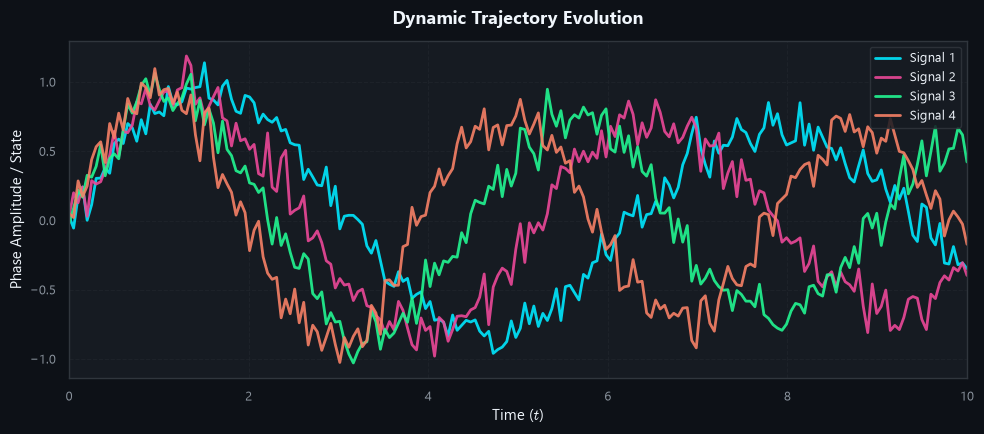

In [2]:
# Set deterministic seed
rng = np.random.default_rng(42)

# Synthesize sample trajectory data
time = np.linspace(0, 10, 200)
n_signals = 4
signals = np.array([
    np.sin(time * (1.0 + 0.2 * i)) * np.exp(-0.05 * time) + 0.1 * rng.normal(size=len(time))
    for i in range(n_signals)
])

colors = HIGH_CONTRAST_CYCLE[:n_signals]
labels = [f"Signal {i+1}" for i in range(n_signals)]

# Create Time Series Plot
fig, ax = plt.subplots(figsize=(10, 4.5))
for i in range(n_signals):
    ax.plot(time, signals[i], label=labels[i], color=colors[i], linewidth=2.0, alpha=0.9)

ax.set_title("Dynamic Trajectory Evolution", fontsize=13, fontweight="bold", pad=12, color=TEXT_PRIMARY)
ax.set_xlabel("Time ($t$)", fontsize=11, color=TEXT_PRIMARY)
ax.set_ylabel("Phase Amplitude / State", fontsize=11, color=TEXT_PRIMARY)
ax.legend(loc="upper right", facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=9)
ax.set_xlim(0, 10)
plt.tight_layout()
plt.show()

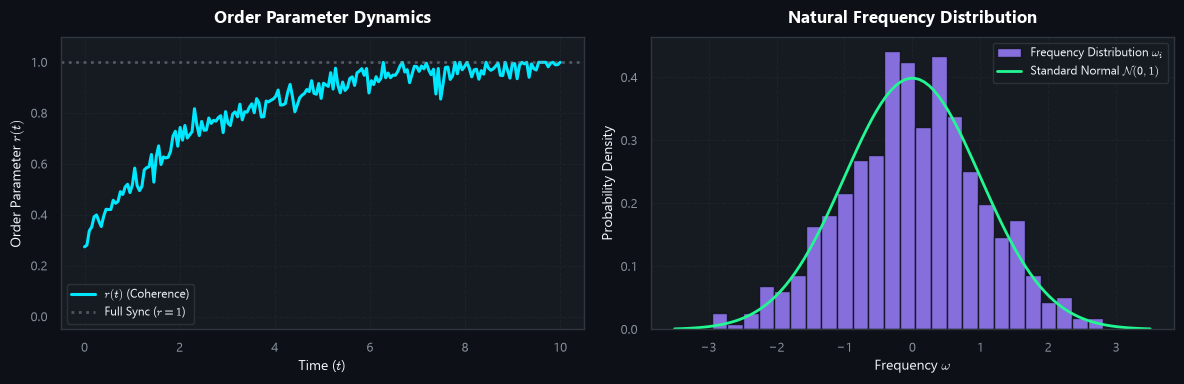

In [3]:
# Synthesize Bounded Metric & Distribution Plot
order_param = 1.0 - 0.7 * np.exp(-0.4 * time) + 0.03 * rng.normal(size=len(time))
order_param = np.clip(order_param, 0.0, 1.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left: Order Parameter Evolution
ax1.plot(time, order_param, color=THEME_TOKENS["primary_light"], linewidth=2.2, label="$r(t)$ (Coherence)")
ax1.axhline(1.0, color=TEXT_MUTED, linestyle=":", alpha=0.5, label="Full Sync ($r=1$)")
ax1.set_title("Order Parameter Dynamics", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Time ($t$)", fontsize=10)
ax1.set_ylabel("Order Parameter $r(t)$", fontsize=10)
ax1.set_ylim(-0.05, 1.1)
ax1.legend(facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=8.5)

# Right: Distribution Histogram
samples = rng.normal(loc=0.0, scale=1.0, size=500)
n_bins, bins, patches = ax2.hist(
    samples, bins=25, density=True, color=THEME_TOKENS["secondary"], 
    edgecolor=THEME_BG, alpha=0.85, label="Frequency Distribution $\\omega_i$"
)
x_fit = np.linspace(-3.5, 3.5, 100)
ax2.plot(x_fit, 1.0 / np.sqrt(2 * np.pi) * np.exp(-0.5 * x_fit**2), color=THEME_TOKENS["tertiary_light"], linewidth=2.0, label="Standard Normal $\\mathcal{N}(0, 1)$")
ax2.set_title("Natural Frequency Distribution", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Frequency $\\omega$", fontsize=10)
ax2.set_ylabel("Probability Density", fontsize=10)
ax2.legend(facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=8.5)

plt.tight_layout()
plt.show()

## 3️⃣ NetworkX Graphs & Topology Styling

### 📖 Educational Note
Complex network graphs and topological diagrams are styled using `NETWORKX_GRAPHS_PALETTE` from `../python/visualization_boilerplate.py`. This section renders four fundamental network structures:
- **Ring Lattice:** Local 1D nearest-neighbor coupling
- **Watts-Strogatz Small-World:** High local clustering with short characteristic path length
- **Erdős-Rényi Random Graph:** Stochastic uniform edge assignment
- **Complete Graph:** All-to-all mean-field coupling

Nodes and edges use tokens from `NETWORKX_GRAPHS_PALETTE`.

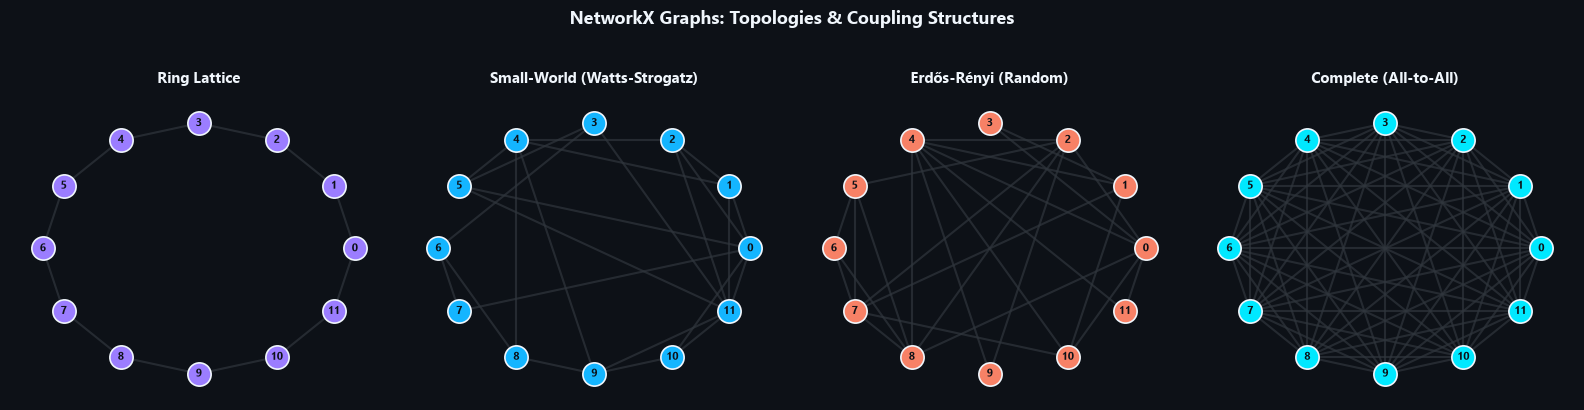

In [4]:
# Generate 4 standard network topologies
n_nodes = 12
graphs: Dict[str, Tuple[nx.Graph, str, str]] = {
    "Ring Lattice": (
        nx.cycle_graph(n_nodes),
        "ring",
        NETWORKX_GRAPHS_PALETTE["ring"]
    ),
    "Small-World (Watts-Strogatz)": (
        nx.watts_strogatz_graph(n=n_nodes, k=4, p=0.3, seed=42),
        "small_world",
        NETWORKX_GRAPHS_PALETTE["small_world"]
    ),
    "Erdős-Rényi (Random)": (
        nx.erdos_renyi_graph(n=n_nodes, p=0.35, seed=42),
        "erdos_renyi",
        NETWORKX_GRAPHS_PALETTE["erdos_renyi"]
    ),
    "Complete (All-to-All)": (
        nx.complete_graph(n_nodes),
        "complete",
        NETWORKX_GRAPHS_PALETTE["complete"]
    ),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes = axes.flatten()

for idx, (title, (G, topo_key, node_color)) in enumerate(graphs.items()):
    ax = axes[idx]
    ax.set_facecolor(CARD_BG)
    
    # Compute circular layout for crisp visual alignment
    pos = nx.circular_layout(G)
    
    # Draw edges
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color=BORDER_COLOR,
        width=1.5,
        alpha=0.7
    )
    
    # Draw nodes
    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=node_color,
        node_size=280,
        edgecolors=TEXT_PRIMARY,
        linewidths=1.2
    )
    
    # Draw node labels
    nx.draw_networkx_labels(
        G, pos, ax=ax,
        font_size=8,
        font_color=THEME_BG,
        font_weight="bold"
    )
    
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=10, color=TEXT_PRIMARY)
    ax.axis("off")

plt.suptitle("NetworkX Graphs: Topologies & Coupling Structures", fontsize=13, fontweight="bold", y=1.02, color=TEXT_PRIMARY)
plt.tight_layout()
plt.show()

## 4️⃣ Multi-Panel Scientific Dashboard

### 📖 Educational Note
Combining multiple subplots (Network structure, phase distribution, time trajectories, order parameter) into a cohesive publication-grade layout with balanced spacing.

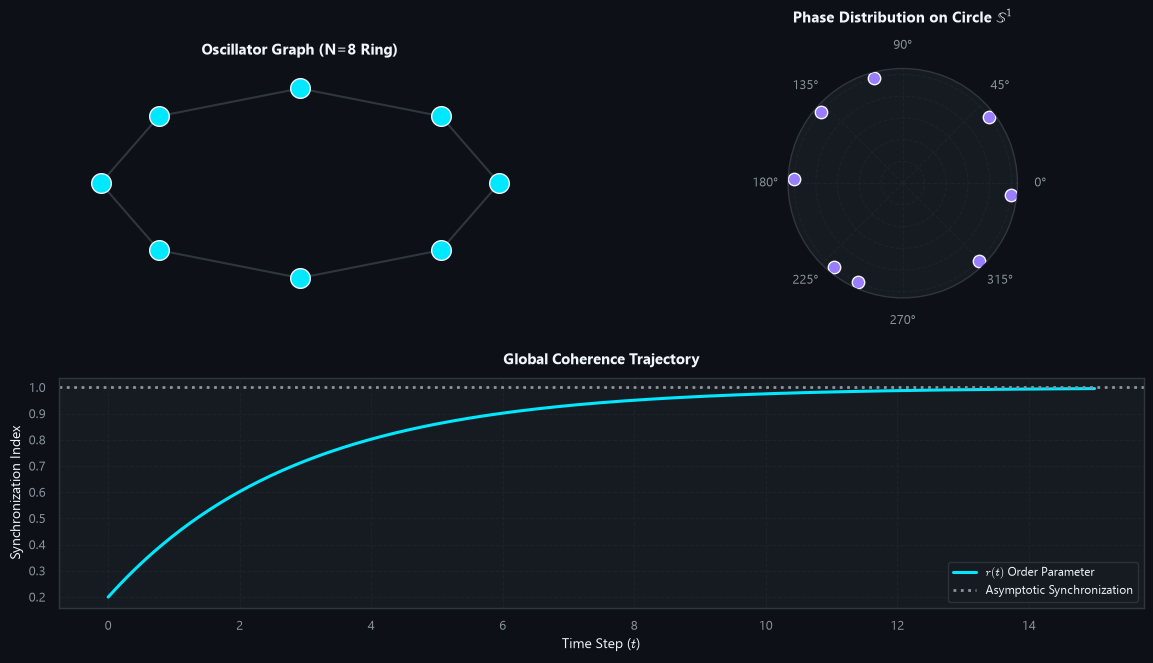

In [5]:
fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

ax_top_left = fig.add_subplot(gs[0, 0])
ax_top_right = fig.add_subplot(gs[0, 1])
ax_bottom = fig.add_subplot(gs[1, :])

# 1. Graph Layout in Top Left
G_sub = nx.cycle_graph(8)
pos_sub = nx.circular_layout(G_sub)
nx.draw_networkx_edges(G_sub, pos_sub, ax=ax_top_left, edge_color=BORDER_COLOR, width=1.5)
nx.draw_networkx_nodes(G_sub, pos_sub, ax=ax_top_left, node_color=THEME_TOKENS["primary_light"], node_size=200, edgecolors=TEXT_PRIMARY)
ax_top_left.set_title("Oscillator Graph (N=8 Ring)", fontsize=11, fontweight="bold", color=TEXT_PRIMARY)
ax_top_left.axis("off")

# 2. Phase Circle (Polar representation) in Top Right
phases_sample = np.linspace(0, 2*np.pi, 8, endpoint=False) + rng.normal(0, 0.2, 8)
ax_top_right.remove()  # Replace with polar subplot
ax_polar = fig.add_subplot(gs[0, 1], projection='polar')
ax_polar.set_facecolor(CARD_BG)
ax_polar.scatter(phases_sample, np.ones_like(phases_sample), color=THEME_TOKENS["secondary"], s=80, edgecolors=TEXT_PRIMARY, zorder=5)
ax_polar.set_yticklabels([])
ax_polar.set_title("Phase Distribution on Circle $\\mathbb{S}^1$", fontsize=11, fontweight="bold", pad=12, color=TEXT_PRIMARY)

# 3. Time Series & Order Parameter Dynamics on Bottom
t_axis = np.linspace(0, 15, 300)
r_dynamics = 1.0 - 0.8 * np.exp(-0.35 * t_axis)
ax_bottom.plot(t_axis, r_dynamics, color=THEME_TOKENS["primary_light"], linewidth=2.2, label="$r(t)$ Order Parameter")
ax_bottom.axhline(1.0, color=TEXT_MUTED, linestyle=":", label="Asymptotic Synchronization")
ax_bottom.set_title("Global Coherence Trajectory", fontsize=11, fontweight="bold", color=TEXT_PRIMARY)
ax_bottom.set_xlabel("Time Step ($t$)", fontsize=10)
ax_bottom.set_ylabel("Synchronization Index", fontsize=10)
ax_bottom.legend(facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=8.5, loc="lower right")

plt.show()

## 5️⃣ High-Contrast Heatmaps & Matrices

### 📖 Educational Note
Demonstrates the three canonical heatmap styles conforming to the Eigenscribe high-contrast standard:
- **Pink-to-Blue (`pink_to_blue`):** High-contrast diverging/bipolar gradient for differential activations and phase correlations.
- **Light Blue-to-Dark Blue (`light_blue_to_dark_blue`):** Crisp sequential gradient for dynamic ranges, intensities, and amplitudes.
- **Light Green-to-Dark Green (`light_green_to_dark_green`):** STEM-focused sequential gradient for synchronization indices, energy metrics, and coherence.

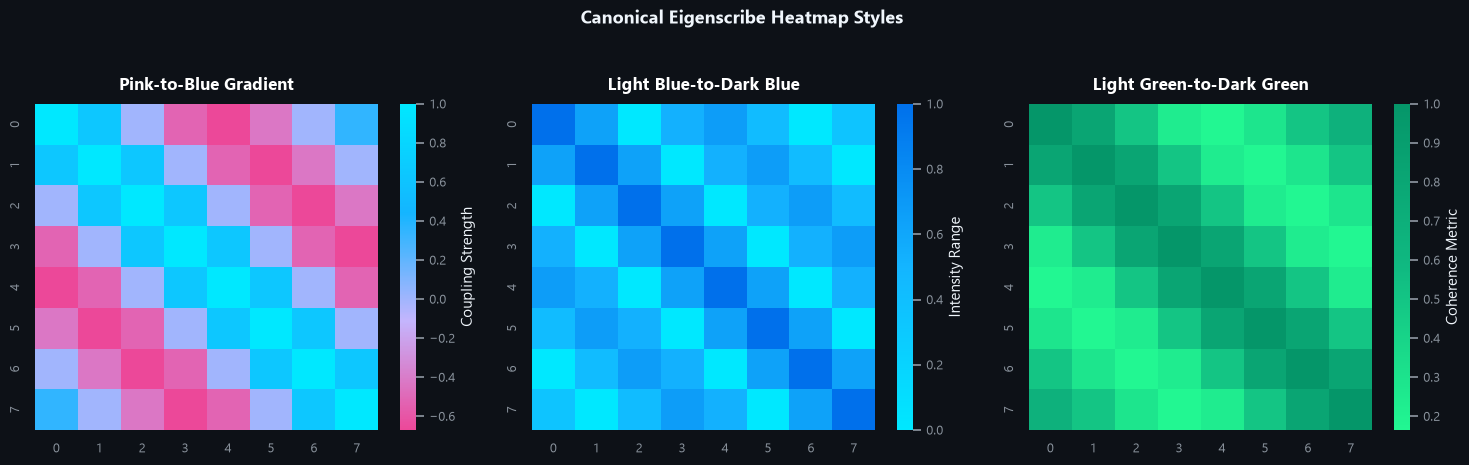

In [6]:
# Synthesize correlation/coupling matrix
n_dim = 8
mock_matrix = np.zeros((n_dim, n_dim))
for i in range(n_dim):
    for j in range(n_dim):
        mock_matrix[i, j] = np.cos((i - j) * np.pi / 4.0) * np.exp(-0.1 * abs(i - j))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Style 1: Pink to Blue
plot_eigenscribe_heatmap(
    mock_matrix,
    style="pink_to_blue",
    ax=axes[0],
    title="Pink-to-Blue Gradient",
    cbar_label="Coupling Strength"
)

# Style 2: Light Blue to Dark Blue
plot_eigenscribe_heatmap(
    np.abs(mock_matrix),
    style="light_blue_to_dark_blue",
    ax=axes[1],
    title="Light Blue-to-Dark Blue",
    cbar_label="Intensity Range"
)

# Style 3: Light Green to Dark Green
plot_eigenscribe_heatmap(
    (mock_matrix + 1.0) / 2.0,
    style="light_green_to_dark_green",
    ax=axes[2],
    title="Light Green-to-Dark Green",
    cbar_label="Coherence Metric"
)

plt.suptitle("Canonical Eigenscribe Heatmap Styles", fontsize=13, fontweight="bold", y=1.03, color=TEXT_PRIMARY)
plt.tight_layout()
plt.show()

## 6️⃣ Color Palettes & Semantic Colormaps

### 📖 Educational Note
This section showcases all design tokens, categorical comparison swatches (`COMPARISON_PALETTES`: Style 1, NetworkX Graphs, Style 3), and continuous colormaps (`SEMANTIC_COLORMAPS`) loaded directly from `../python/visualization_boilerplate.py`.

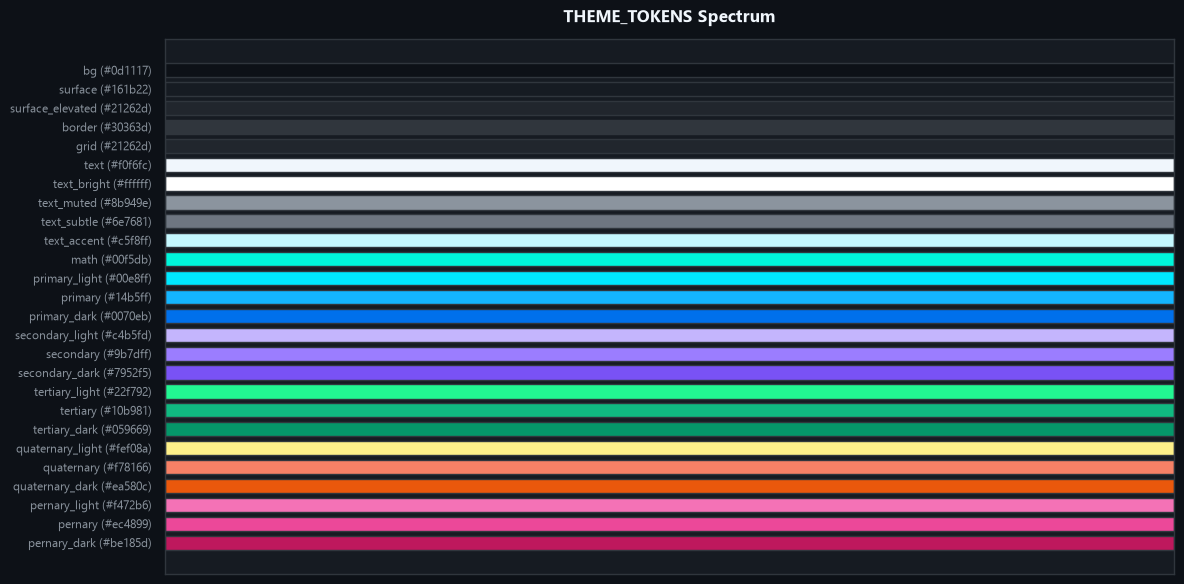

In [7]:
# Render all project color tokens
token_names = list(THEME_TOKENS.keys())
token_hexes = list(THEME_TOKENS.values())
n_tokens = len(token_names)

fig, ax = plt.subplots(figsize=(12, 6))
y_positions = np.arange(n_tokens)

ax.barh(y_positions, np.ones(n_tokens), color=token_hexes, edgecolor=BORDER_COLOR, height=0.75)
ax.set_yticks(y_positions)
ax.set_yticklabels([f"{name} ({hex_val})" for name, hex_val in zip(token_names, token_hexes)], fontsize=8.5)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.invert_yaxis()
ax.set_title("THEME_TOKENS Spectrum", fontsize=12, fontweight="bold", pad=12, color=TEXT_PRIMARY)
plt.tight_layout()
plt.show()

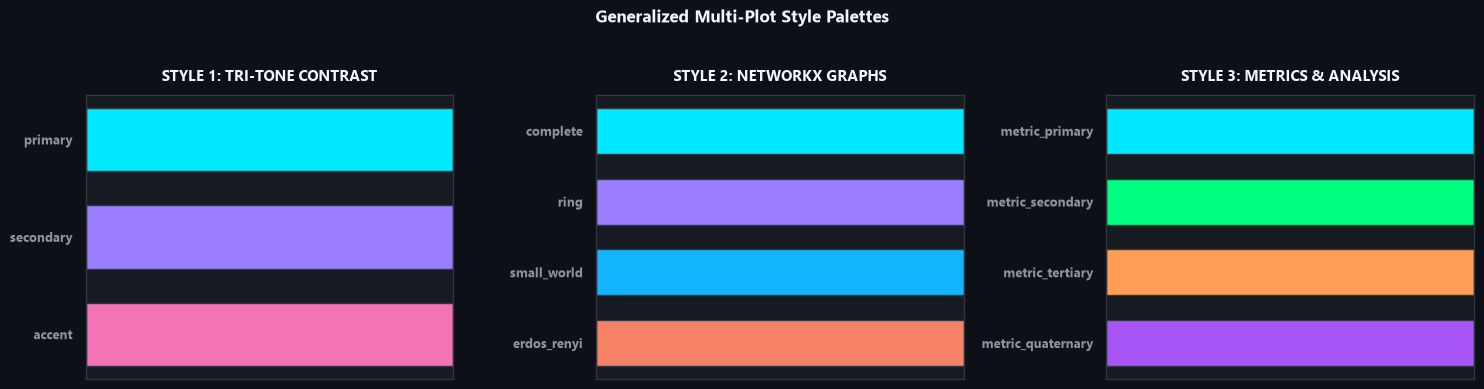

In [8]:
# Render comparison palettes: Style 1, NetworkX Graphs, Style 3
palette_display_names = {
    "style_1": "STYLE 1: TRI-TONE CONTRAST",
    "networkx_graphs": "STYLE 2: NETWORKX GRAPHS",
    "style_3": "STYLE 3: METRICS & ANALYSIS",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

for idx, (cat_key, cat_dict) in enumerate(COMPARISON_PALETTES.items()):
    ax = axes[idx]
    keys = list(cat_dict.keys())
    colors_list = list(cat_dict.values())
    y_pos = np.arange(len(keys))
    
    ax.barh(y_pos, np.ones(len(keys)), color=colors_list, edgecolor=BORDER_COLOR, height=0.65)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(keys, fontsize=9.5, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_xticks([])
    ax.invert_yaxis()
    disp_title = palette_display_names.get(cat_key, cat_key.upper().replace("_", " "))
    ax.set_title(disp_title, fontsize=10.5, fontweight="bold", pad=10, color=TEXT_PRIMARY)

plt.suptitle("Generalized Multi-Plot Style Palettes", fontsize=12.5, fontweight="bold", y=1.02, color=TEXT_PRIMARY)
plt.tight_layout()
plt.show()

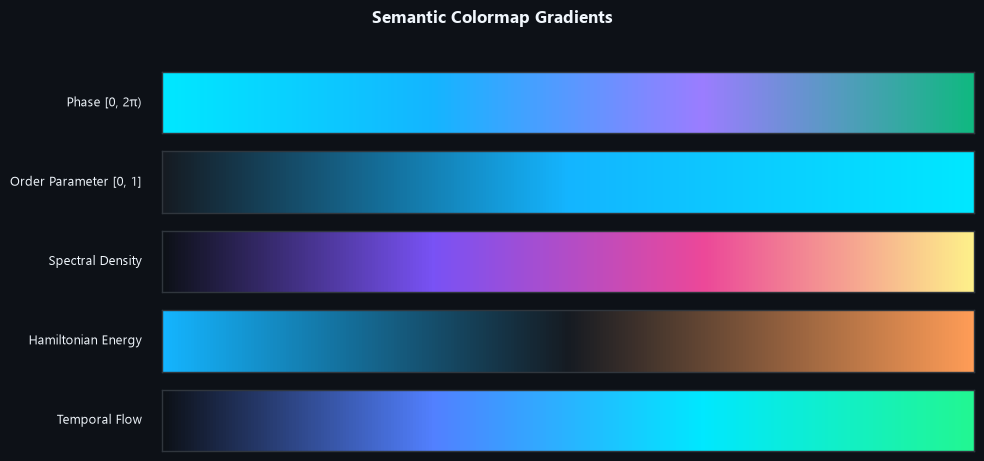

🎉 Visuals & Graph Styling Boilerplate execution complete.


In [9]:
# Display semantic colormaps from visualization_boilerplate
fig, axes = plt.subplots(len(SEMANTIC_COLORMAPS), 1, figsize=(10, 4.5))
gradient = np.linspace(0, 1, 256).reshape(1, -1)

for idx, (cmap_name, cmap_obj) in enumerate(SEMANTIC_COLORMAPS.items()):
    ax = axes[idx]
    ax.imshow(gradient, aspect="auto", cmap=cmap_obj)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_ylabel(cmap_name, rotation=0, ha="right", va="center", fontsize=9, color=TEXT_PRIMARY, labelpad=15)

plt.suptitle("Semantic Colormap Gradients", fontsize=12, fontweight="bold", y=1.02, color=TEXT_PRIMARY)
plt.tight_layout()
plt.show()

print("🎉 Visuals & Graph Styling Boilerplate execution complete.")
